# Phishing website detector: data exploration
Goal: build a model that tells if a website is phishing or legitimate.
Dataset: about 11,000 websites with 30 features each.

In [393]:
import pandas as pd
df = pd.read_csv("../data/phishing.csv")
print(df.shape)

(11054, 32)


In [394]:
df.head()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


In [395]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    11054 non-nu

In [396]:
df["class"].value_counts()

class
 1    6157
-1    4897
Name: count, dtype: int64

In [397]:
df.isna().sum().sum()

np.int64(0)

## Data quality
All columns are numbers and there are no missing values, so no cleaning is needed for gaps.

In [398]:
df.groupby("class")[["HTTPS", "AgeofDomain", "DNSRecording", "PageRank"]].mean()

,HTTPS,AgeofDomain,DNSRecording,PageRank
class,,,,
-1,-0.479681,-0.074535,0.298754,-0.586277
1,0.832223,0.169401,0.439662,-0.401981


In [399]:
df = df.drop(columns=["Index"])

In [400]:
df["label"] = df["class"].map({-1: "phishing", 1: "legitimate"})

In [401]:
df.drop(columns=["label"]).duplicated().sum()

np.int64(5205)

<Axes: xlabel='label'>

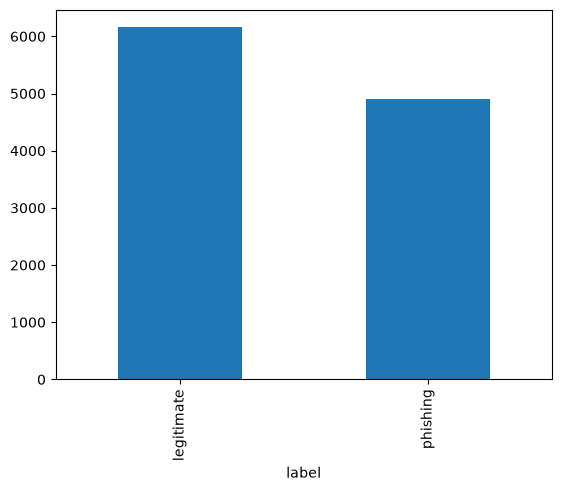

In [402]:
df["label"].value_counts().plot(kind="bar")

## Class balance
There are 6,157 legitimate and 4,897 phishing websites. The classes are fairly balanced.
A model that always says "legitimate" would be right about 55.7% of the time, so that is the baseline to beat.

In [403]:
features = df.drop(columns=["class", "label"])
features.duplicated().sum()

np.int64(5269)

In [404]:
df.groupby(list(features.columns))["class"].nunique().gt(1).sum()

np.int64(64)

In [405]:
df_unique = df.drop(columns=["label"]).drop_duplicates()
print(df_unique.shape)
df_unique["class"].value_counts(normalize=True)

(5849, 31)


class
-1    0.516157
 1    0.483843
Name: proportion, dtype: float64

## Which class is phishing?
Class -1 has lower averages on features like HTTPS and PageRank. In this dataset, -1 means "suspicious" and 1 means "legitimate", so I treat -1 as phishing.

## Duplicates
5,205 rows are duplicates, almost half of the data. If the same row is in both the training set and the test set, the model sees the answers before the test and the score looks too good.
Decision: remove duplicates before splitting the data.

In [406]:
features = df.drop(columns=["class", "label"])
features.duplicated().sum()

np.int64(5269)

In [407]:
df.groupby(list(features.columns))["class"].nunique().gt(1).sum()

np.int64(64)

In [408]:
df_unique = df.drop(columns=["label"]).drop_duplicates()
print(df_unique.shape)
df_unique["class"].value_counts(normalize=True)

(5849, 31)


class
-1    0.516157
 1    0.483843
Name: proportion, dtype: float64

In [409]:
print(df_unique.shape)
print(df_clean.shape)

(5849, 31)
(5721, 31)


In [410]:
df_clean["class"].value_counts(normalize=True)

class
-1    0.516518
 1    0.483482
Name: proportion, dtype: float64

In [411]:
df_clean.to_csv("../data/phishing_clean.csv", index=False)

In [412]:
import pandas as pd
check = pd.read_csv("../data/phishing_clean.csv")
print(check.shape)
print(check.columns.tolist()[-3:])

(5721, 31)
['LinksPointingToPage', 'StatsReport', 'class']


In [413]:
df_clean["class"].value_counts(normalize=True)

class
-1    0.516518
 1    0.483482
Name: proportion, dtype: float64

i removed 47% exact duplicates and 64 conflicting patterns, the final size is 5,721 rows, and the baseline is 51.65%.